# 04 · Baselines (Stage 1)
**Goal:** set the bar *before* any machine learning. A model is only useful if it beats these simple rules on the same test rows.

| Baseline | Rule (forecast made at time t for t+h) |
|---|---|
| Persistence | CF(t+h) = CF(t) |
| Smart persistence | keep the clear-sky index of time t, then rescale by clear-sky output at t+h |
| Seasonal naive | same hour on the latest day known at t (yesterday for h ≤ 24, 2 days back for h ≤ 48) |
| Climatology | average CF for that month and local hour, computed on the training set only |

**Evaluation protocol**
- Chronological split: the oldest 80 % is train and the newest 20 % is test. Nothing is shuffled.
- Score on **daytime test hours** only, using the **same rows for every method**.
- Metrics: RMSE, MAE, MBE (bias) and R². CF is a fraction of capacity, so RMSE × 100 = **% of installed capacity**.
- Skill score = 1 − RMSE / RMSE<sub>reference</sub>.

In [1]:
import sys, warnings
sys.path.insert(0, "../src")          # project modules
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid")

from io_utils import FIG, load_processed
from config import SITES, TEST_FRAC
from evaluation import all_baselines, evaluate, fit_clearsky_scale, metrics, skill

HORIZONS = [1, 2, 3, 4, 5, 6, 24, 36, 48]
data = {s: load_processed(s) for s in ("primary", "site_a")}

## 1. Train/test split and clear-sky scaling
Smart persistence needs the clear-sky CF, i.e. how much the plant produces under a clear sky. The scale factor is fitted on **training data only**.

In [2]:
split = {}
for s, d in data.items():
    cut = d.index[int(len(d) * (1 - TEST_FRAC))]
    train = d[d.index < cut]
    split[s] = {"cut": cut, "train": train, "scale": fit_clearsky_scale(train),
                "test_mask": (d.index >= cut) & (d["is_day"] == 1)}
    print(f"{s}: train {train.index.min().date()} -> {cut.date()} | test {cut.date()} -> {d.index.max().date()} "
          f"| clear-sky CF per W/m2 = {split[s]['scale']:.5f}")

primary: train 2023-12-31 -> 2025-09-16 | test 2025-09-16 -> 2026-02-19 | clear-sky CF per W/m2 = 0.00099
site_a: train 2025-01-03 -> 2026-03-14 | test 2026-03-14 -> 2026-06-30 | clear-sky CF per W/m2 = 0.00101


## 2. Score every baseline at every horizon

In [3]:
rows, preds_store = [], {}
for s, d in data.items():
    sp = split[s]
    for h in HORIZONS:
        preds = all_baselines(d, sp["train"], h, SITES[s]["tz"], sp["scale"])
        preds_store[(s, h)] = preds
        res = evaluate(d, preds, sp["test_mask"])
        for model, r in res.iterrows():
            rows.append({"site": s, "horizon_h": h, "model": model, **r.to_dict()})

results = pd.DataFrame(rows)
results["RMSE_%cap"] = results["RMSE"] * 100
results["MAE_%cap"] = results["MAE"] * 100

In [4]:
# RMSE (% of capacity), lower is better
results.pivot_table(index=["site", "model"], columns="horizon_h", values="RMSE_%cap").round(2)

horizon_h                     1      2      3      4      5      6      24     36     48
site    model                                                                           
primary climatology        15.38  15.38  15.38  15.38  15.38  15.38  15.38  15.36  15.38
        persistence        16.85  29.69  40.02  48.01  53.78  57.58  17.10  59.24  18.61
        seasonal_naive     17.10  17.10  17.10  17.10  17.10  17.10  17.10  18.37  18.61
        smart_persistence   8.46  11.53  13.66  15.42  16.68  17.72  17.11  20.53  18.64
site_a  climatology        17.13  17.13  17.13  17.13  17.13  17.13  17.14  16.91  16.92
        persistence        15.79  26.61  35.46  42.50  47.71  50.99  21.15  49.09  21.29
        seasonal_naive     21.14  21.14  21.14  21.14  21.14  21.14  21.15  21.29  21.29
        smart_persistence  11.04  15.62  18.84  21.64  23.96  25.62  21.17  28.78  21.35

In [5]:
# R2 (higher is better)
results.pivot_table(index=["site", "model"], columns="horizon_h", values="R2").round(3)

horizon_h                     1      2      3      4      5      6      24     36     48
site    model                                                                           
primary climatology        0.775  0.775  0.775  0.775  0.775  0.775  0.775  0.776  0.775
        persistence        0.730  0.163 -0.521 -1.189 -1.747 -2.151  0.722 -2.335  0.671
        seasonal_naive     0.722  0.722  0.722  0.722  0.722  0.722  0.722  0.679  0.671
        smart_persistence  0.932  0.874  0.823  0.774  0.736  0.702  0.722  0.600  0.670
site_a  climatology        0.676  0.676  0.676  0.676  0.676  0.676  0.676  0.685  0.684
        persistence        0.725  0.220 -0.386 -0.991 -1.510 -1.866  0.507 -1.658  0.500
        seasonal_naive     0.507  0.507  0.507  0.507  0.507  0.507  0.507  0.500  0.500
        smart_persistence  0.866  0.731  0.609  0.484  0.367  0.276  0.506  0.087  0.497

## 3. RMSE vs horizon

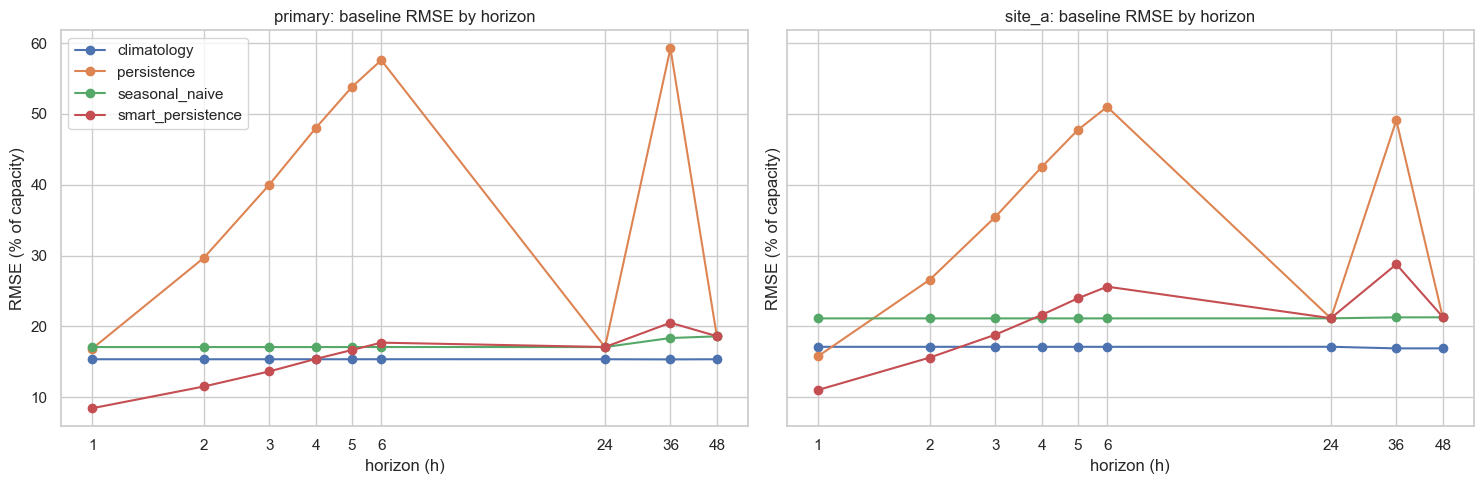

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(15, 5), sharey=True)
for i, s in enumerate(data):
    r = results[results["site"] == s]
    for m, g in r.groupby("model"):
        ax[i].plot(g["horizon_h"], g["RMSE_%cap"], marker="o", label=m)
    ax[i].set_title(f"{s}: baseline RMSE by horizon"); ax[i].set_xlabel("horizon (h)")
    ax[i].set_ylabel("RMSE (% of capacity)"); ax[i].set_xscale("log"); ax[i].set_xticks(HORIZONS, HORIZONS)
ax[0].legend()
fig.tight_layout(); fig.savefig(FIG / "11_baseline_rmse_by_horizon.png", dpi=120); plt.show()

## 4. Skill of each baseline against plain persistence
Positive values mean the baseline beats persistence.

In [7]:
pers = results[results["model"] == "persistence"].set_index(["site", "horizon_h"])["RMSE"]
results["skill_vs_persistence"] = [skill(r.RMSE, pers[(r.site, r.horizon_h)]) for r in results.itertuples()]
results.pivot_table(index=["site", "model"], columns="horizon_h", values="skill_vs_persistence").round(3)

horizon_h                     1      2      3      4      5      6      24     36     48
site    model                                                                           
primary climatology        0.088  0.482  0.616  0.680  0.714  0.733  0.101  0.741  0.174
        persistence        0.000  0.000  0.000  0.000  0.000  0.000  0.000  0.000  0.000
        seasonal_naive    -0.014  0.424  0.573  0.644  0.682  0.703  0.000  0.690  0.000
        smart_persistence  0.498  0.612  0.659  0.679  0.690  0.692 -0.000  0.653 -0.001
site_a  climatology       -0.085  0.356  0.517  0.597  0.641  0.664  0.190  0.656  0.206
        persistence        0.000  0.000  0.000  0.000  0.000  0.000  0.000  0.000  0.000
        seasonal_naive    -0.339  0.205  0.404  0.503  0.557  0.585  0.000  0.566  0.000
        smart_persistence  0.301  0.413  0.469  0.491  0.498  0.498 -0.001  0.414 -0.003

## 5. The reference to beat at each horizon
Later models report **skill against the best baseline at each horizon** (not against the weakest one), which keeps the comparison honest.

In [8]:
best = results.loc[results.groupby(["site", "horizon_h"])["RMSE"].idxmin(),
                   ["site", "horizon_h", "model", "RMSE_%cap", "MAE_%cap", "R2"]]
best.round(3)

,site,horizon_h,model,RMSE_%cap,MAE_%cap,R2
1,primary,1,smart_persistence,8.461,4.893,0.932
5,primary,2,smart_persistence,11.535,7.047,0.874
9,primary,3,smart_persistence,13.664,8.420,0.823
15,primary,4,climatology,15.376,11.364,0.775
19,primary,5,climatology,15.376,11.364,0.775
23,primary,6,climatology,15.380,11.369,0.775
27,primary,24,climatology,15.376,11.364,0.775
31,primary,36,climatology,15.355,11.338,0.776
35,primary,48,climatology,15.376,11.364,0.775
37,site_a,1,smart_persistence,11.039,6.853,0.866


## 6. Error by season and sky condition (smart persistence, h = 1 and h = 24)

In [9]:
SEASON = {12: "DJF", 1: "DJF", 2: "DJF", 3: "MAM", 4: "MAM", 5: "MAM",
          6: "JJA", 7: "JJA", 8: "JJA", 9: "SON", 10: "SON", 11: "SON"}
strat = []
for s, d in data.items():
    loc = d.index.tz_convert(SITES[s]["tz"])
    groups = {"season": pd.Series(loc.month, index=d.index).map(SEASON),
              "sky": pd.cut(d["clearsky_index"], [0, .4, .8, 1.6], labels=["overcast", "partly", "clear"]).astype(str).replace("nan", "low sun")}
    for h in (1, 24):
        p = preds_store[(s, h)]["smart_persistence"]
        ok = split[s]["test_mask"] & d["capacity_factor"].notna() & p.notna()
        for gname, g in groups.items():
            for val in g[ok].unique():
                m = ok & (g == val)
                if m.sum() >= 30:
                    strat.append({"site": s, "h": h, "by": gname, "group": val,
                                  "RMSE_%cap": metrics(d.loc[m, "capacity_factor"], p[m])["RMSE"] * 100, "n": int(m.sum())})
pd.DataFrame(strat).pivot_table(index=["site", "by", "group"], columns="h", values="RMSE_%cap").round(2)

h                           1      24
site    by     group                 
primary season DJF        8.04  14.54
               SON        8.92  19.65
        sky    clear      6.44  14.65
               low sun    0.70   0.76
               overcast  14.01  31.12
               partly    13.04  19.85
site_a  season JJA       10.72  17.68
               MAM       11.23  22.53
        sky    clear     10.02  19.00
               low sun    0.69   0.73
               overcast  10.12  28.18
               partly    13.73  24.19

## 7. Example forecasts on a test week

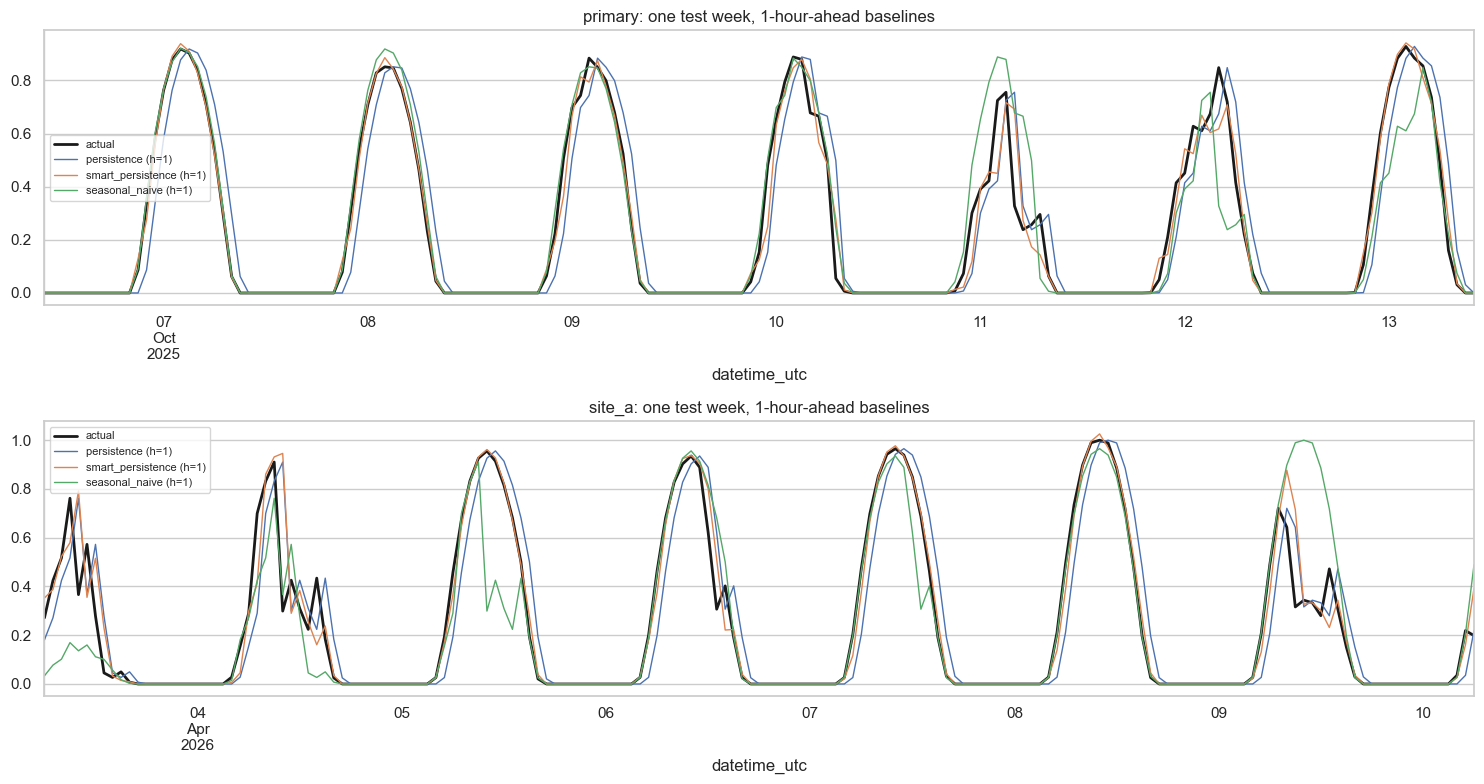

In [10]:
fig, ax = plt.subplots(2, 1, figsize=(15, 8))
for i, (s, d) in enumerate(data.items()):
    start = split[s]["cut"] + pd.Timedelta(days=20)
    w = slice(start, start + pd.Timedelta(days=7))
    d.loc[w, "capacity_factor"].plot(ax=ax[i], color="k", lw=2, label="actual")
    for m in ("persistence", "smart_persistence", "seasonal_naive"):
        preds_store[(s, 1)].loc[w, m].plot(ax=ax[i], lw=1, label=f"{m} (h=1)")
    ax[i].set_title(f"{s}: one test week, 1-hour-ahead baselines"); ax[i].legend(fontsize=8)
fig.tight_layout(); fig.savefig(FIG / "12_baseline_example_week.png", dpi=120); plt.show()

In [11]:
results.round(5).to_csv("../reports/baseline_results.csv", index=False)
print("saved reports/baseline_results.csv")

saved reports/baseline_results.csv


## Findings
1. **Smart persistence is the bar for short horizons.** At h = 1 its RMSE is **8.5 %** of capacity (primary, R² 0.93) and **11.0 %** (Site A, R² 0.87), roughly half the error of plain persistence. Rescaling by clear-sky output removes the error caused by the sun moving.
2. **Plain persistence falls apart after 2 h** (R² < 0 by h = 3), because the sun's position changes. It only recovers at multiples of 24 h, where it becomes seasonal naive.
3. **From about 3 to 4 h onward, climatology is the best baseline** (≈ 15.4 % primary, ≈ 17.1 % Site A). Beyond a few hours, the average for that month and hour beats copying the recent past.
4. **Site A is harder** at every horizon (cloudier climate), as the EDA predicted. At the primary site, overcast and partly cloudy hours have about **2×** the error of clear hours. At Site A the gap appears mainly at h = 24 (28 % overcast vs 19 % clear). This is the room where weather inputs should help the ML models (see section 6).
5. **The targets for the ML models (Weeks 6–8):** beat smart persistence at 1–2 h and climatology at 3–48 h. This answers research questions RQ1 and RQ2: the gap between the model and these curves is the real skill.